In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [30]:
train_df = pd.read_csv('../data/processed/train_df.csv')
test_df = pd.read_csv('../data/processed/test_df.csv')
rul_df = pd.read_csv('../data/processed/rul_df.csv')


In [31]:
print(f"amount of missing values in train_df :\n{train_df.isna().sum()} ")

amount of missing values in train_df :
unit_id      0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
dtype: int64 


In [32]:
print(f"unique values in train_df: \n{train_df.nunique()}")

unique values in train_df: 
unit_id       100
cycle         362
setting_1     158
setting_2      13
setting_3       1
sensor_1        1
sensor_2      310
sensor_3     3012
sensor_4     4051
sensor_5        1
sensor_6        2
sensor_7      513
sensor_8       53
sensor_9     6403
sensor_10       1
sensor_11     159
sensor_12     427
sensor_13      56
sensor_14    6078
sensor_15    1918
sensor_16       1
sensor_17      13
sensor_18       1
sensor_19       1
sensor_20     120
sensor_21    4745
dtype: int64


In [33]:
# compute columns with few sd
few_sd_columns = train_df.columns[train_df.std() < 0.1]
print(f"columns with few sd: \n{few_sd_columns}")

columns with few sd: 
Index(['setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_5',
       'sensor_6', 'sensor_8', 'sensor_10', 'sensor_13', 'sensor_15',
       'sensor_16', 'sensor_18', 'sensor_19'],
      dtype='object')


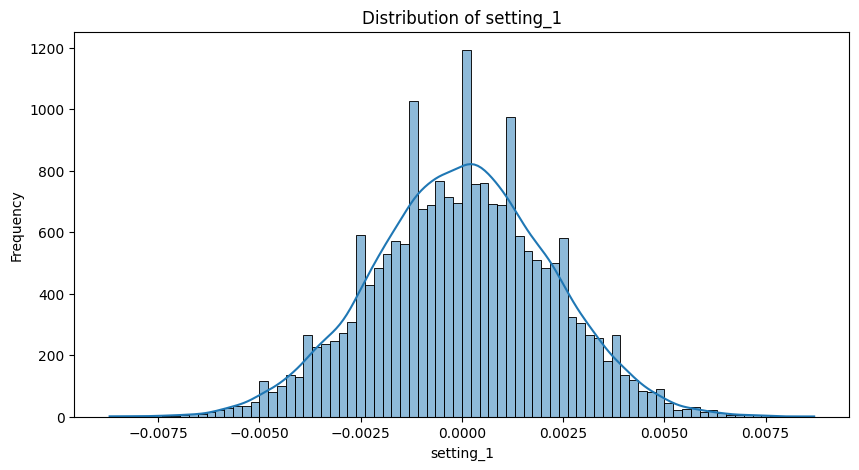

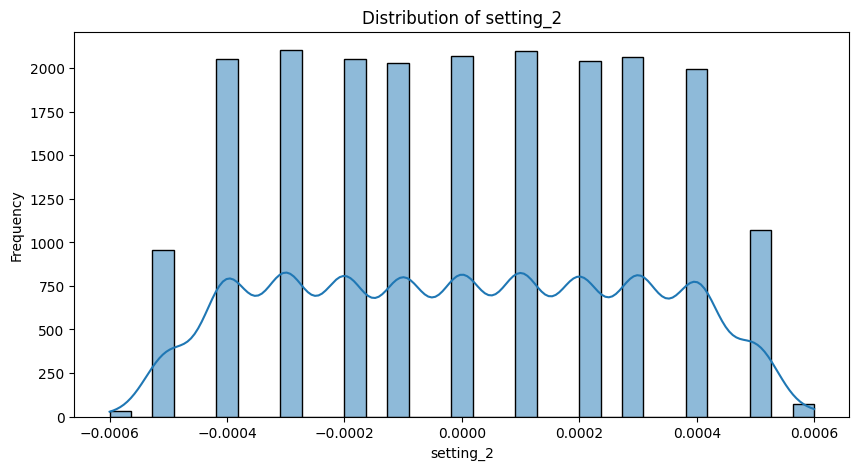

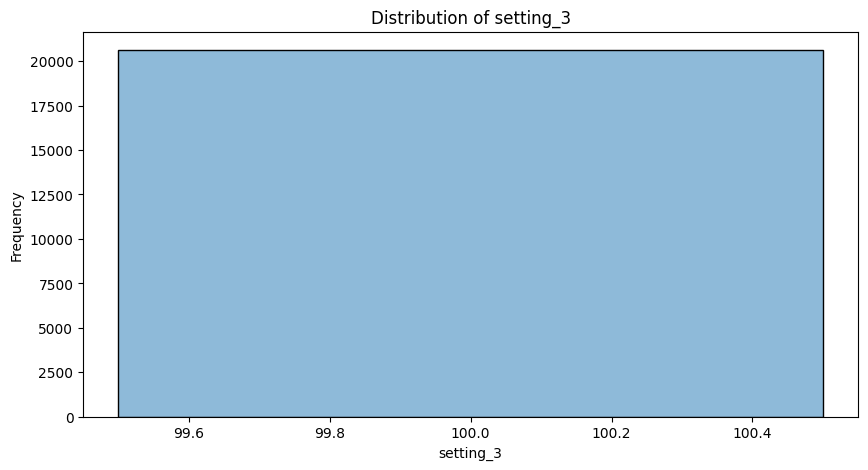

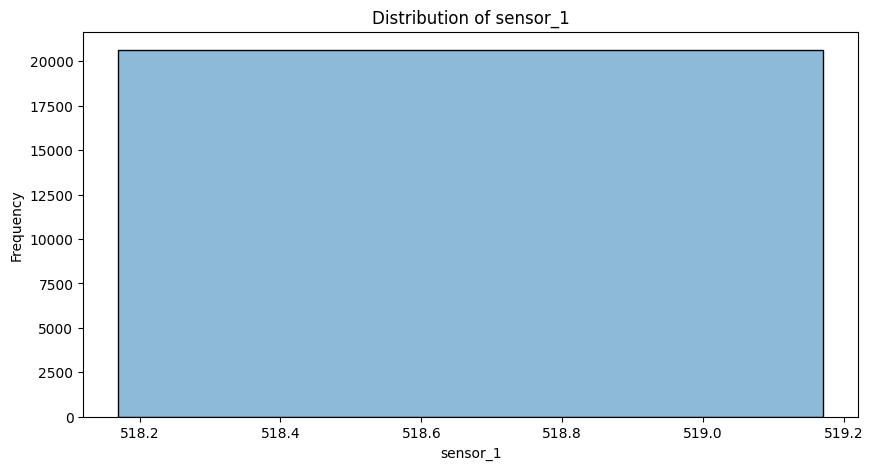

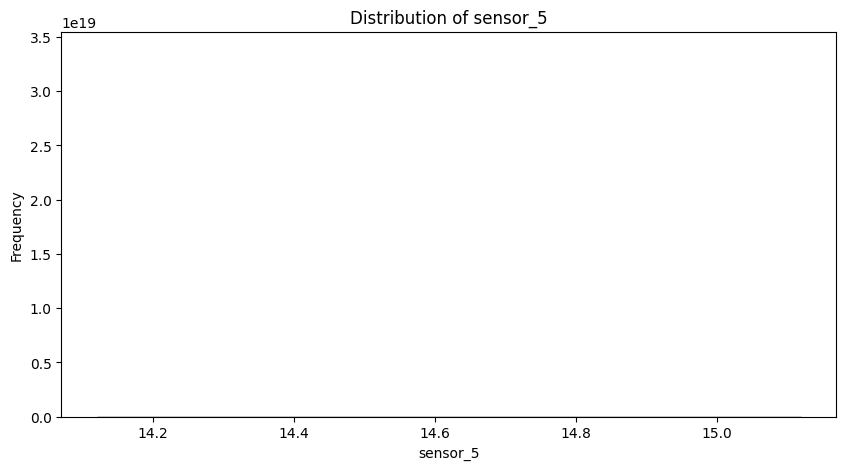

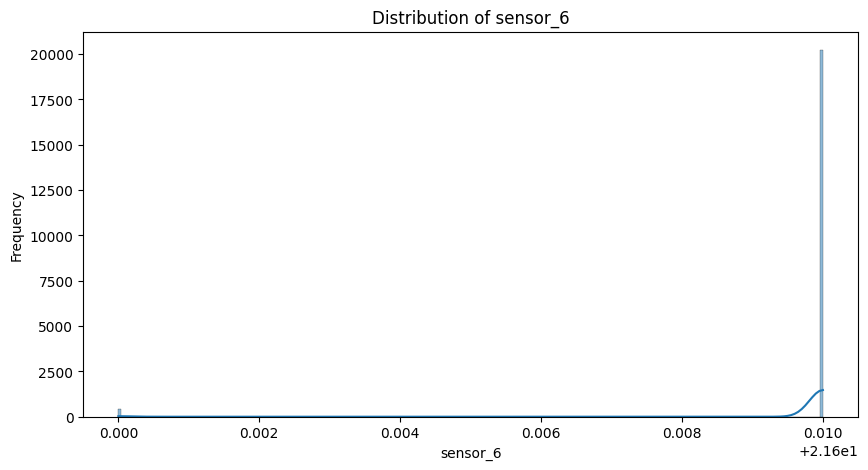

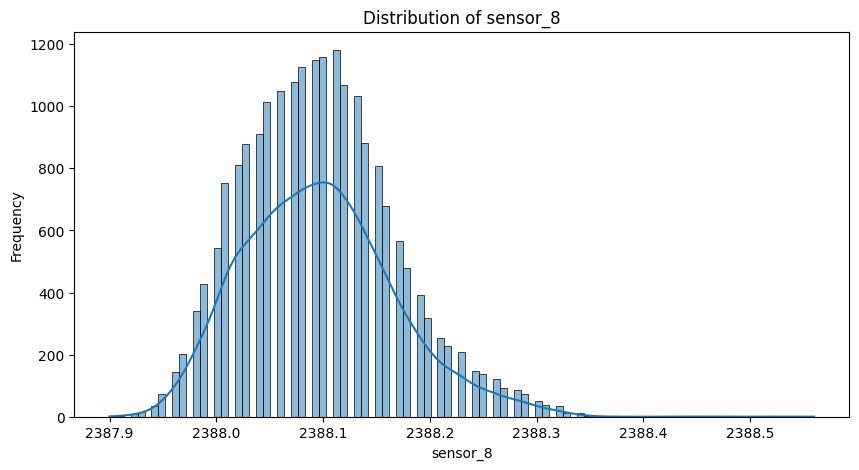

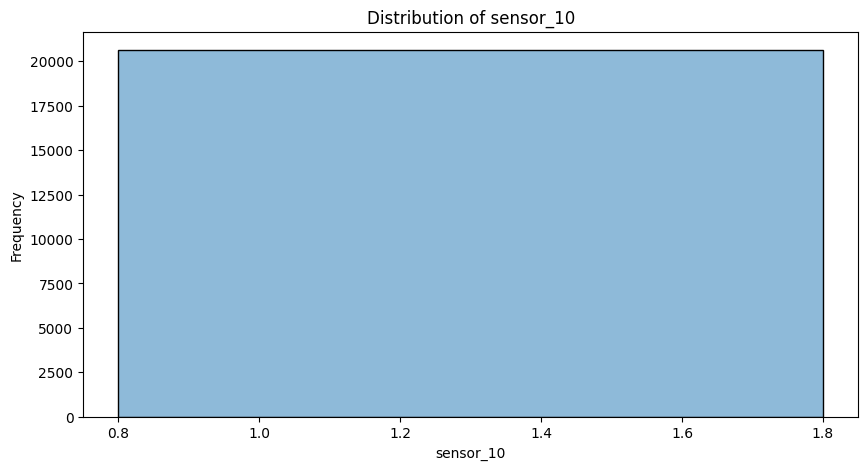

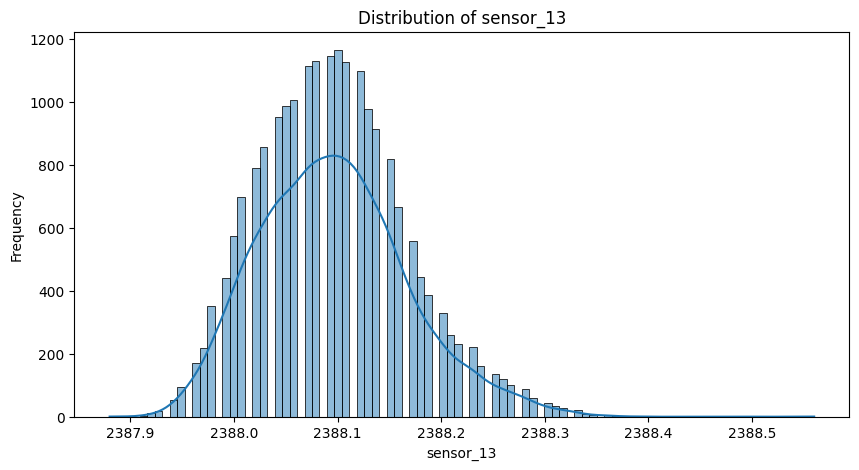

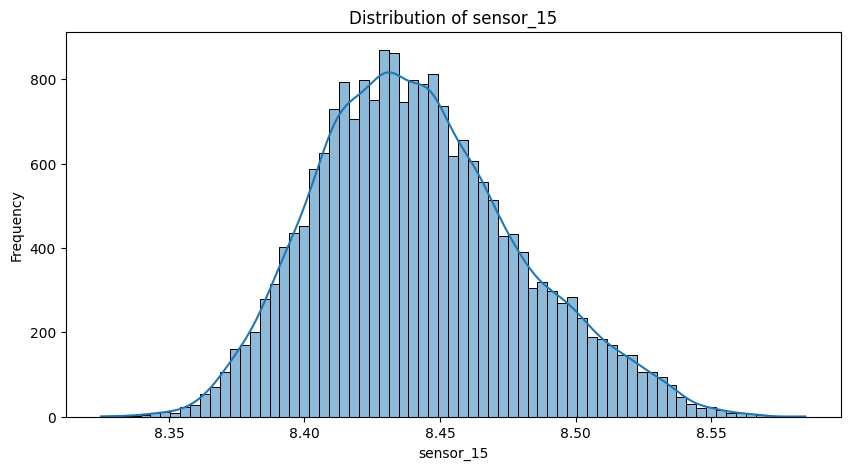

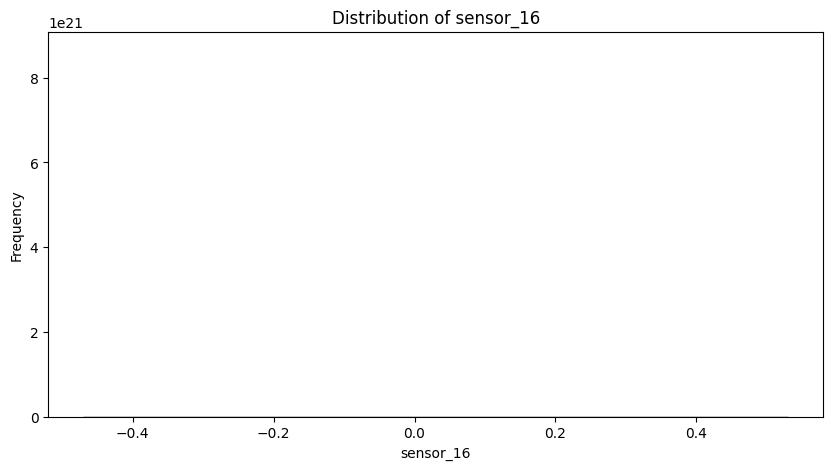

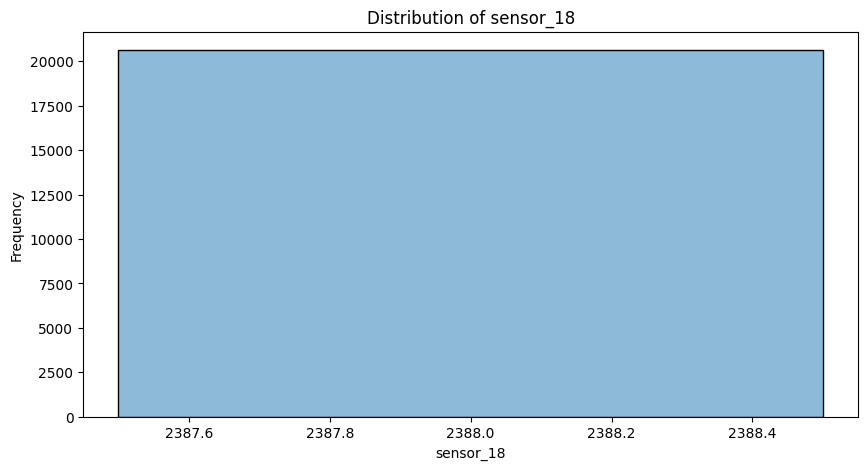

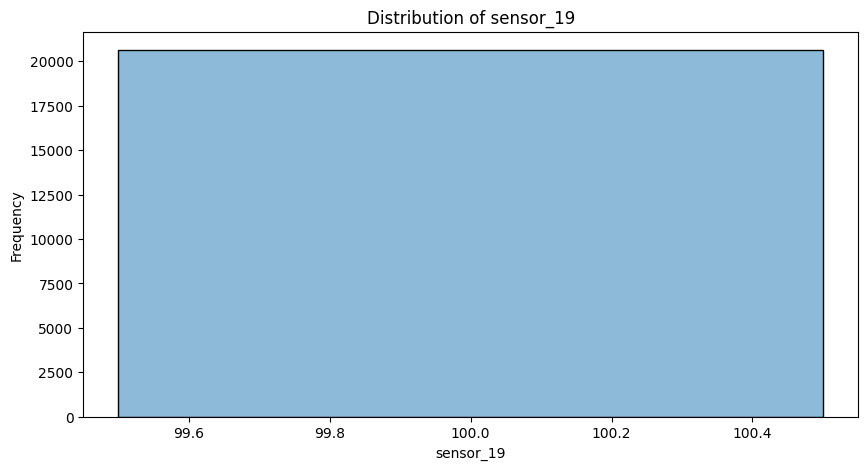

In [34]:
# plot the distribution of the few sd columns
for col in few_sd_columns:
    plt.figure(figsize=(10, 5))
    sns.histplot(train_df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

In [35]:
max_cycle=train_df.groupby("unit_id")["cycle"].transform("max")
train_df["RUL"] = max_cycle - train_df["cycle"]

max_cycle_test=test_df.groupby("unit_id")["cycle"].transform("max")
test_df["RUL"] = max_cycle_test - test_df["cycle"]

In [36]:
useful_columns = train_df.columns[train_df.std() > 0.01].tolist()
useful_columns.remove("unit_id")
useful_columns.remove("cycle")
features = ["setting_1", "setting_2", "setting_3"] + useful_columns 
features.remove("RUL")
print(f"Features: {features}")

Features: ['setting_1', 'setting_2', 'setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [37]:
test_df

,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735,30
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916,29
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166,28
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737,27
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130,26
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13091,100,194,0.0049,0.0000,100.0,518.67,643.24,1599.45,1415.79,14.62,...,2388.00,8213.28,8.4715,0.03,394,2388,100.0,38.65,23.1974,4
13092,100,195,-0.0011,-0.0001,100.0,518.67,643.22,1595.69,1422.05,14.62,...,2388.09,8210.85,8.4512,0.03,395,2388,100.0,38.57,23.2771,3
13093,100,196,-0.0006,-0.0003,100.0,518.67,643.44,1593.15,1406.82,14.62,...,2388.04,8217.24,8.4569,0.03,395,2388,100.0,38.62,23.2051,2
13094,100,197,-0.0038,0.0001,100.0,518.67,643.26,1594.99,1419.36,14.62,...,2388.08,8220.48,8.4711,0.03,395,2388,100.0,38.66,23.2699,1


In [38]:
target = "RUL"
amount_of_train = range(0 , 81)
amount_of_val = range(81 , 101)


x_train = train_df.where(train_df['unit_id'].isin(amount_of_train))[features].dropna()
y_train = train_df.where(train_df['unit_id'].isin(amount_of_train))[target].dropna()
x_val = train_df.where(train_df['unit_id'].isin(amount_of_val))[features].dropna()
y_val = train_df.where(train_df['unit_id'].isin(amount_of_val))[target].dropna()
x_test = test_df[features].dropna()
y_test = test_df[target].dropna()

In [39]:
x_train.to_csv('../data/processed/x_train.csv', index=False)
y_train.to_csv('../data/processed/y_train.csv', index=False)
x_val.to_csv('../data/processed/x_val.csv', index=False)
y_val.to_csv('../data/processed/y_val.csv', index=False)
x_test.to_csv('../data/processed/x_test.csv', index=False)
y_test.to_csv('../data/processed/y_test.csv', index=False)

In [40]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled = scaler.transform(x_val)
x_test_scaled = scaler.transform(x_test)


In [41]:
import joblib
joblib.dump(scaler, '../models/scaler.pkl')

['../models/scaler.pkl']

In [42]:
x_train_scaled = pd.DataFrame(x_train_scaled, columns=features)
x_val_scaled = pd.DataFrame(x_val_scaled, columns=features)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=features)

In [43]:
x_train_scaled.to_csv('../data/processed/x_train_scaled.csv', index=False)
x_val_scaled.to_csv('../data/processed/x_val_scaled.csv', index=False)
x_test_scaled.to_csv('../data/processed/x_test_scaled.csv', index=False)